<a href="https://colab.research.google.com/github/Subhash-Pal/Rodic-infra-Colab/blob/main/Rodic_Edge_CV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import os
import shutil

# Forcefully unmount if already mounted
os.system("usr/bin/fusermount -uz /content/drive 2>/dev/null")

32512

In [ ]:

# If the directory still exists and contains leftovers, remove it to ensure a clean slate
if os.path.exists('/content/drive'):
    try:
        shutil.rmtree('/content/drive')
    except Exception:
        pass

# Mount the drive safely
drive.mount('/content/drive', force_remount=True)

# List the outputs directory to verify successful access
!ls -l /content/drive/MyDrive/rodic-poc-project/outputs/

Mounted at /content/drive
total 89372
-rw------- 1 root root    46373 Oct  7 06:32 '1 (6)_annotated.jpg'
-rw------- 1 root root    45992 Oct  7 05:46 '1 (6)_best_codebrim_annotated.jpg'
-rw------- 1 root root      339 Oct  7 05:46 '1 (6)_best_codebrim_report.json'
-rw------- 1 root root    50414 Oct  7 05:47 '1 (6)_best_sdnet_annotated.jpg'
-rw------- 1 root root      670 Oct  7 05:47 '1 (6)_best_sdnet_report.json'
-rw------- 1 root root      339 Oct  7 06:32 '1 (6)_report.json'
-rw------- 1 root root    46016 Oct  7 11:45  1_best_codebrim_annotated.jpg
-rw------- 1 root root      339 Oct  7 11:45  1_best_codebrim_report.json
-rw------- 1 root root    50512 Oct  7 11:45  1_best_sdnet_annotated.jpg
-rw------- 1 root root      670 Oct  7 11:45  1_best_sdnet_report.json
-rw------- 1 root root    86498 Oct  6 04:37  3_best_codebrim_annotated.jpg
-rw------- 1 root root        2 Oct  6 04:37  3_best_codebrim_report.json
-rw------- 1 root root    75566 Oct  6 04:37 '6 (1)_best_codebrim_annota

In [ ]:
# @rodic — Step 1: Baseline benchmark before edge optimization
# Read-only with respect to existing models/modules.
# Creates one new additive report: outputs/edge_baseline_benchmark.json

import gc
import json
import os
import sys
import time
import statistics
from pathlib import Path

try:
    import psutil
    import torch

    ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
    OUTPUT_DIR = ROOT / "outputs"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    required = [
        ROOT / "src" / "model.py",
        ROOT / "outputs" / "best_codebrim.pt",
        ROOT / "outputs" / "best_sdnet.pt",
        ROOT / "outputs" / "codebrim_evaluation.json",
        ROOT / "outputs" / "sdnet_evaluation.json",
    ]
    missing = [str(p) for p in required if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "Required project artifacts are missing:\n" + "\n".join(missing)
        )

    sys.path.insert(0, str(ROOT))
    from src.model import build_model

    process = psutil.Process(os.getpid())
    device = torch.device("cpu")  # Baseline for CPU-compatible quantization
    results = {
        "benchmark_type": "baseline_before_edge_optimization",
        "device": str(device),
        "input_shape": [1, 3, 224, 224],
        "timing_scope": "model_forward_only; preprocessing excluded",
        "timing_method": "warmup_then_batch_size_1; same method required for comparison",
        "models": {},
    }

    def load_state(checkpoint_path):
        try:
            obj = torch.load(
                checkpoint_path, map_location="cpu", weights_only=True
            )
        except TypeError:
            obj = torch.load(checkpoint_path, map_location="cpu")

        if isinstance(obj, dict):
            for key in ("state_dict", "model_state_dict", "model"):
                if key in obj and isinstance(obj[key], dict):
                    obj = obj[key]
                    break

        if not isinstance(obj, dict):
            raise TypeError(f"Unsupported checkpoint structure: {checkpoint_path}")

        # Handle DataParallel checkpoints without changing saved files.
        if obj and all(k.startswith("module.") for k in obj):
            obj = {k[len("module."):]: v for k, v in obj.items()}

        return obj

    for name, task, checkpoint_name, evaluation_name in [
        ("CODEBRIM", "codebrim", "best_codebrim.pt",
         "codebrim_evaluation.json"),
        ("SDNET2018", "sdnet", "best_sdnet.pt",
         "sdnet_evaluation.json"),
    ]:
        checkpoint_path = OUTPUT_DIR / checkpoint_name
        evaluation_path = OUTPUT_DIR / evaluation_name

        with open(evaluation_path, "r", encoding="utf-8") as f:
            evaluation = json.load(f)

        metrics = evaluation.get("evaluation", {}).get("metrics", {})
        f1_metrics = {
            key: value for key, value in metrics.items()
            if "f1" in key.lower()
        }

        rss_before_mb = process.memory_info().rss / (1024 ** 2)
        model = build_model(task)
        state = load_state(checkpoint_path)
        model.load_state_dict(state, strict=True)
        model.to(device).eval()
        rss_after_load_mb = process.memory_info().rss / (1024 ** 2)

        # Synthetic input measures forward-pass latency, not image preprocessing.
        sample = torch.randn(1, 3, 224, 224, device=device)

        with torch.inference_mode():
            for _ in range(20):
                model(sample)

            timings_ms = []
            for _ in range(100):
                start = time.perf_counter()
                model(sample)
                timings_ms.append((time.perf_counter() - start) * 1000)

        sorted_timings = sorted(timings_ms)
        p95_index = min(
            len(sorted_timings) - 1,
            int(0.95 * len(sorted_timings))
        )

        results["models"][name] = {
            "checkpoint": checkpoint_name,
            "checkpoint_size_mb": round(
                checkpoint_path.stat().st_size / (1024 ** 2), 3
            ),
            "parameter_count": sum(p.numel() for p in model.parameters()),
            "f1_metrics_from_existing_evaluation": f1_metrics,
            "warmup_runs": 20,
            "timed_runs": len(timings_ms),
            "forward_latency_median_ms": round(
                statistics.median(timings_ms), 3
            ),
            "forward_latency_p95_ms": round(
                sorted_timings[p95_index], 3
            ),
            "process_rss_before_load_mb": round(rss_before_mb, 2),
            "process_rss_after_load_mb": round(rss_after_load_mb, 2),
            "rss_delta_during_load_mb": round(
                rss_after_load_mb - rss_before_mb, 2
            ),
            "memory_note": (
                "Process RSS delta is an approximate load-time memory change, "
                "not isolated model memory. It can include allocator/runtime overhead."
            ),
        }

        print(f"\n{name}")
        print("Checkpoint size (MB):",
              results["models"][name]["checkpoint_size_mb"])
        print("Existing F1 metrics:", f1_metrics)
        print("Median forward latency (ms):",
              results["models"][name]["forward_latency_median_ms"])
        print("P95 forward latency (ms):",
              results["models"][name]["forward_latency_p95_ms"])
        print("Process RSS after load (MB):",
              results["models"][name]["process_rss_after_load_mb"])

        del model, state, sample
        gc.collect()

    report_path = OUTPUT_DIR / "edge_baseline_benchmark.json"
    with open(report_path, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2)

    print("\nBaseline report:", report_path)
    print("SUCCESS: Original-model baseline recorded; existing modules unchanged.")

except Exception as exc:
    print(f"FAILED: Baseline benchmark did not complete: {type(exc).__name__}: {exc}")
    raise


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]



CODEBRIM
Checkpoint size (MB): 42.723
Existing F1 metrics: {'micro_f1': 0.8279569892473119, 'macro_f1': 0.8256017678598976}
Median forward latency (ms): 50.572
P95 forward latency (ms): 62.544
Process RSS after load (MB): 776.78

SDNET2018
Checkpoint size (MB): 42.715
Existing F1 metrics: {'f1': 0.8353380340107839}
Median forward latency (ms): 51.46
P95 forward latency (ms): 78.901
Process RSS after load (MB): 810.57

Baseline report: /content/drive/MyDrive/rodic-poc-project/outputs/edge_baseline_benchmark.json
SUCCESS: Original-model baseline recorded; existing modules unchanged.


In [ ]:

# STEP 2 — Read-only inspection before INT8 quantization
# No original checkpoints, source files, or evaluation reports are modified.

from pathlib import Path
import json
import sys

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
OUT = ROOT / "outputs"

try:
    if not ROOT.exists():
        raise FileNotFoundError(f"Project root not found: {ROOT}")
    if not (OUT / "edge_baseline_benchmark.json").exists():
        raise FileNotFoundError("Baseline benchmark JSON is missing.")

    print("=== 1. BASELINE BENCHMARK ===")
    baseline = json.loads(
        (OUT / "edge_baseline_benchmark.json").read_text()
    )
    print(json.dumps(baseline, indent=2)[:10000])

    print("\n=== 2. RELEVANT PROJECT FILES ===")
    for folder_name in ["src", "outputs", "tests"]:
        folder = ROOT / folder_name
        if folder.exists():
            print(f"\n[{folder_name}/]")
            for p in sorted(folder.rglob("*")):
                if p.is_file() and (
                    p.suffix.lower() in {
                        ".py", ".json", ".yaml", ".yml",
                        ".txt", ".csv", ".pt", ".pth"
                    }
                ):
                    print(f"{p.relative_to(ROOT)} ({p.stat().st_size:,} bytes)")

    print("\n=== 3. EVALUATION JSON STRUCTURES ===")
    for name in [
        "codebrim_evaluation.json",
        "sdnet_evaluation.json",
        "sdnet_evaluation_split.json",
    ]:
        p = OUT / name
        if p.exists():
            print(f"\n--- {name} ---")
            try:
                obj = json.loads(p.read_text())
                print(json.dumps(obj, indent=2)[:5000])
            except Exception as e:
                print(f"Could not parse JSON: {e}")

    print("\n=== 4. MODEL AND CONFIG SOURCE (READ ONLY) ===")
    for name in ["src/model.py", "src/config.py"]:
        p = ROOT / name
        print(f"\n--- {name} ---")
        if p.exists():
            print(p.read_text(errors="replace")[:12000])
        else:
            print("File not found.")

    print("\n=== 5. ENVIRONMENT ===")
    print("Python:", sys.version.split()[0])
    try:
        import torch
        print("PyTorch:", torch.__version__)
        print("Dynamic quantization API available:",
              hasattr(torch.ao.quantization, "quantize_dynamic"))
    except Exception as e:
        print("PyTorch inspection error:", repr(e))

    print("\nSUCCESS: Read-only inspection completed; project files unchanged.")

except Exception as e:
    print(f"\nFAILED: {type(e).__name__}: {e}")


=== 1. BASELINE BENCHMARK ===
{
  "benchmark_type": "baseline_before_edge_optimization",
  "device": "cpu",
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "timing_scope": "model_forward_only; preprocessing excluded",
  "timing_method": "warmup_then_batch_size_1; same method required for comparison",
  "models": {
    "CODEBRIM": {
      "checkpoint": "best_codebrim.pt",
      "checkpoint_size_mb": 42.723,
      "parameter_count": 11179590,
      "f1_metrics_from_existing_evaluation": {
        "micro_f1": 0.8279569892473119,
        "macro_f1": 0.8256017678598976
      },
      "warmup_runs": 20,
      "timed_runs": 100,
      "forward_latency_median_ms": 50.572,
      "forward_latency_p95_ms": 62.544,
      "process_rss_before_load_mb": 688.75,
      "process_rss_after_load_mb": 776.78,
      "rss_delta_during_load_mb": 88.03,
      "memory_note": "Process RSS delta is an approximate load-time memory change, not isolated model memory. It can include allocator/runtime overhea

In [ ]:

# STEP 3 — Dynamic INT8 compatibility check
# Read-only: does not load or overwrite project checkpoints.

from pathlib import Path
import torch
import torch.nn as nn

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
OUT = ROOT / "outputs"

try:
    assert ROOT.exists(), f"Project root not found: {ROOT}"
    assert (OUT / "edge_baseline_benchmark.json").exists(), \
        "Baseline report not found."

    print("PyTorch version:", torch.__version__)
    print("Device: CPU")
    print("Dynamic quantization API:",
          hasattr(torch.ao.quantization, "quantize_dynamic"))

    # Verify quantization on a disposable Linear-layer model.
    test_model = nn.Sequential(
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 6)
    ).eval()

    test_input = torch.randn(1, 128)

    with torch.inference_mode():
        fp32_output = test_model(test_input)

    int8_model = torch.ao.quantization.quantize_dynamic(
        test_model,
        {nn.Linear},
        dtype=torch.qint8
    ).eval()

    with torch.inference_mode():
        int8_output = int8_model(test_input)

    max_abs_diff = (fp32_output - int8_output).abs().max().item()
    quantized_linear_layers = sum(
        "quantized" in type(module).__module__.lower()
        for module in int8_model.modules()
        if isinstance(module, nn.Module)
    )

    print("FP32 output shape:", tuple(fp32_output.shape))
    print("INT8 output shape:", tuple(int8_output.shape))
    print("Maximum absolute output difference:", round(max_abs_diff, 6))
    print("Quantized module types:",
          sorted({type(m).__name__ for m in int8_model.modules()}))

    print("\nSUCCESS: Dynamic INT8 compatibility check completed; "
          "original project files unchanged.")

except Exception as e:
    print(f"\nFAILED: {type(e).__name__}: {e}")


PyTorch version: 2.11.0+cu130
Device: CPU
Dynamic quantization API: True
FP32 output shape: (1, 6)
INT8 output shape: (1, 6)
Maximum absolute output difference: 0.003194
Quantized module types: ['Linear', 'LinearPackedParams', 'ReLU', 'Sequential']

SUCCESS: Dynamic INT8 compatibility check completed; original project files unchanged.


/tmp/ipykernel_3052/323834871.py:33: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.ao.quantization.quantize_dynamic(


In [ ]:

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
OUT = ROOT / "outputs"

try:
    model_path = ROOT / "src" / "model.py"
    if not model_path.exists():
        raise FileNotFoundError(f"Missing: {model_path}")

    print("=== src/model.py ===")
    print(model_path.read_text(errors="replace")[:16000])

    for name in [
        "codebrim_evaluation.json",
        "sdnet_evaluation.json",
        "sdnet_evaluation_split.json",
    ]:
        path = OUT / name
        print(f"\n=== {name} ===")
        if not path.exists():
            print("NOT FOUND")
            continue

        data = json.loads(path.read_text())

        # Show the schema and a small sample, not a potentially huge report.
        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys()))
        print(json.dumps(data, indent=2)[:3500])

    print("\nSUCCESS: Model/evaluation inspection complete; files unchanged.")

except Exception as e:
    print(f"\nFAILED: {type(e).__name__}: {e}")


=== src/model.py ===
import torch
import torch.nn as nn
from torchvision import models

from . import config


class DefectClassifier(nn.Module):
    def __init__(self, num_classes: int, pretrained: bool = True):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
        in_features = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.head = nn.Linear(in_features, num_classes)

    def forward(self, x):
        features = self.backbone(x)
        return self.head(features)


def build_model(task: str, pretrained: bool = True) -> DefectClassifier:
    if task == "codebrim":
        return DefectClassifier(num_classes=len(config.CODEBRIM_CLASSES), pretrained=pretrained)
    if task == "sdnet":
        return DefectClassifier(num_classes=1, pretrained=pretrained)
    raise ValueError(f"Unknown task: {task}")


=== codebrim_evaluation.json ===
Top-level keys: [

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
SRC = ROOT / "src"

try:
    if not ROOT.exists():
        raise FileNotFoundError(f"Project root not found: {ROOT}")

    print("=== Project scripts ===")
    for folder in [SRC, ROOT]:
        if folder.exists():
            for path in sorted(folder.iterdir()):
                if path.is_file() and (
                    path.suffix == ".py"
                    or path.name.lower().startswith(("eval", "test", "train"))
                ):
                    print(path.relative_to(ROOT))

    print("\n=== Relevant evaluation / dataset code ===")
    candidates = []
    for path in SRC.rglob("*.py"):
        name = path.name.lower()
        if any(term in name for term in (
            "eval", "dataset", "data", "train", "inference"
        )):
            candidates.append(path)

    for path in sorted(set(candidates)):
        print(f"\n--- {path.relative_to(ROOT)} ---")
        print(path.read_text(errors="replace")[:7000])

    print("\nSUCCESS: Pipeline inspection completed; no project files modified.")

except Exception as e:
    print(f"\nFAILED: {type(e).__name__}: {e}")


=== Project scripts ===
src/__init__.py
src/config.py
src/dataset.py
src/evaluator.py
src/model.py
src/overlay.py
src/severity_stub.py
src/severity_vlm.py
src/sliding_window.py
src/train.py
main_demo.py
rodic_package.py

=== Relevant evaluation / dataset code ===

--- src/dataset.py ---
from pathlib import Path
from typing import List, Tuple
import xml.etree.ElementTree as ET

import torch
from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image

from . import config

DEFAULT_TRANSFORM = transforms.Compose([
    transforms.Resize((config.IMAGE_SIZE, config.IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

_XML_TAGS = ["Background", "Crack", "Spallation", "Efflorescence", "ExposedBars", "CorrosionStain"]


def _load_defect_labels(metadata_dir: Path) -> dict:
    labels = {}
    xml_path = metadata_dir / "defects.xml"
    if not xml_path.exists():
        raise FileNotFoundErr

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")

FILES = [
    "src/evaluator.py",
    "src/model.py",
    "src/config.py",
    "main_demo.py",
    "src/severity_vlm.py",
    "src/overlay.py",
]

for relative_path in FILES:
    path = ROOT / relative_path
    print(f"\n{'=' * 24} {relative_path} {'=' * 24}")

    if not path.is_file():
        print("NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()
    print(f"Total lines: {len(lines)}")

    # Print the complete file in numbered form.
    for number, line in enumerate(lines, start=1):
        print(f"{number:4}: {line}")

print("\nInspection complete. No project files modified.")



======================== src/evaluator.py ========================
Total lines: 1409
   1: 
   2: from pathlib import Path
   3: import json
   4: import time
   5: from datetime import datetime
   6: 
   7: import numpy as np
   8: import torch
   9: 
  10: from sklearn.metrics import (
  11:     accuracy_score,
  12:     precision_score,
  13:     recall_score,
  14:     f1_score,
  15:     confusion_matrix,
  16:     roc_auc_score,
  17:     average_precision_score,
  18: )
  19: 
  20: 
  21: class RODICModelEvaluator:
  22:     """
  23:     Production-oriented evaluator for RODIC InfraAI models.
  24: 
  25:     Supports:
  26:         - CODEBRIM: multi-label classification
  27:         - SDNET2018: binary classification
  28: 
  29:     Important distinction:
  30: 
  31:         model_task
  32:             Actual task name expected by src.model.build_model()
  33:             Example:
  34:                 "codebrim"
  35:                 "sdnet"
  36: 
  37:         evaluat

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")

for relative_path in [
    "src/sliding_window.py",
    "src/severity_stub.py",
]:
    path = ROOT / relative_path
    print(f"\n{'=' * 20} {relative_path} {'=' * 20}")

    if not path.is_file():
        print("NOT FOUND")
        continue

    for number, line in enumerate(
        path.read_text(errors="replace").splitlines(), start=1
    ):
        print(f"{number:4}: {line}")

print("\n=== Existing model checkpoints ===")
for folder in [ROOT / "outputs", ROOT]:
    if folder.exists():
        for path in sorted(folder.glob("*.pt")):
            print(
                f"{path.relative_to(ROOT)} | "
                f"{path.stat().st_size / (1024**2):.2f} MiB"
            )

print("\nSUCCESS: Read-only inspection complete.")



==================== src/sliding_window.py ====================
   1: from dataclasses import dataclass
   2: from typing import List
   3: 
   4: import torch
   5: from PIL import Image
   6: from torchvision import transforms
   7: 
   8: from . import config
   9: 
  10: 
  11: @dataclass
  12: class Detection:
  13:     x1: int
  14:     y1: int
  15:     x2: int
  16:     y2: int
  17:     class_name: str
  18:     confidence: float
  19: 
  20: 
  21: def _iou(box_a, box_b) -> float:
  22:     ax1, ay1, ax2, ay2 = box_a
  23:     bx1, by1, bx2, by2 = box_b
  24:     inter_x1, inter_y1 = max(ax1, bx1), max(ay1, by1)
  25:     inter_x2, inter_y2 = min(ax2, bx2), min(ay2, by2)
  26:     inter_area = max(0, inter_x2 - inter_x1) * max(0, inter_y2 - inter_y1)
  27:     area_a = (ax2 - ax1) * (ay2 - ay1)
  28:     area_b = (bx2 - bx1) * (by2 - by1)
  29:     union = area_a + area_b - inter_area
  30:     return inter_area / union if union > 0 else 0.0
  31: 
  32: 
  33: def _nms(dete

In [ ]:

def current_starts(dimension, window=224, stride=112):
    return list(range(0, max(1, dimension - window + 1), stride))

def boundary_aware_starts(dimension, window=224, stride=112):
    if dimension <= window:
        return [0]
    starts = list(range(0, dimension - window + 1, stride))
    last_start = dimension - window
    if starts[-1] != last_start:
        starts.append(last_start)
    return starts

for width, height in [(500, 350), (640, 480), (224, 224), (180, 180)]:
    print(f"\nImage: {width} x {height}")
    for name, fn in [
        ("Current", current_starts),
        ("Boundary-aware", boundary_aware_starts),
    ]:
        xs, ys = fn(width), fn(height)
        max_x2 = max(xs) + 224
        max_y2 = max(ys) + 224
        print(
            f"{name:15} x={xs}, y={ys}; "
            f"right={max_x2}/{width}, bottom={max_y2}/{height}"
        )

print("\nSUCCESS: Geometry diagnostic complete; no project files modified.")



Image: 500 x 350
Current         x=[0, 112, 224], y=[0, 112]; right=448/500, bottom=336/350
Boundary-aware  x=[0, 112, 224, 276], y=[0, 112, 126]; right=500/500, bottom=350/350

Image: 640 x 480
Current         x=[0, 112, 224, 336], y=[0, 112, 224]; right=560/640, bottom=448/480
Boundary-aware  x=[0, 112, 224, 336, 416], y=[0, 112, 224, 256]; right=640/640, bottom=480/480

Image: 224 x 224
Current         x=[0], y=[0]; right=224/224, bottom=224/224
Boundary-aware  x=[0], y=[0]; right=224/224, bottom=224/224

Image: 180 x 180
Current         x=[0], y=[0]; right=224/180, bottom=224/180
Boundary-aware  x=[0], y=[0]; right=224/180, bottom=224/180

SUCCESS: Geometry diagnostic complete; no project files modified.


In [ ]:

from pathlib import Path
import shutil

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
path = ROOT / "src/sliding_window.py"
backup = path.with_name("sliding_window.py.pre_boundary_fix.bak")

source = path.read_text()

old_loops = """        for y in range(0, max(1, height - window_size + 1), stride):
            for x in range(0, max(1, width - window_size + 1), stride):
                crop = image.crop((x, y, x + window_size, y + window_size))"""

new_loops = """        for y in _window_starts(height, window_size, stride):
            for x in _window_starts(width, window_size, stride):
                crop = image.crop((
                    x, y,
                    min(x + window_size, width),
                    min(y + window_size, height),
                ))"""

old_box = "Detection(x, y, x+window_size, y+window_size, class_name, float(prob))"
new_box = "Detection(x, y, min(x + window_size, width), min(y + window_size, height), class_name, float(prob))"

old_box_binary = "Detection(x, y, x+window_size, y+window_size, class_names[0], prob)"
new_box_binary = "Detection(x, y, min(x + window_size, width), min(y + window_size, height), class_names[0], prob)"

if backup.exists():
    raise FileExistsError(f"Backup already exists; refusing to overwrite: {backup}")

if source.count(old_loops) != 1:
    raise RuntimeError("Expected window-loop code not found exactly once; no changes made.")
if source.count(old_box) != 1 or source.count(old_box_binary) != 1:
    raise RuntimeError("Expected detection-box code not found exactly once; no changes made.")

helper = """def _window_starts(dimension: int, window_size: int, stride: int) -> List[int]:
    if dimension <= 0 or window_size <= 0 or stride <= 0:
        raise ValueError("Image dimensions, window_size, and stride must be positive")
    if dimension <= window_size:
        return [0]

    starts = list(range(0, dimension - window_size + 1, stride))
    final_start = dimension - window_size
    if starts[-1] != final_start:
        starts.append(final_start)
    return starts


"""

marker = "def detect(image, model, device, class_names, multi_label=True,"
if source.count(marker) != 1:
    raise RuntimeError("Expected detect() definition not found exactly once; no changes made.")

updated = source.replace(marker, helper + marker)
updated = updated.replace(old_loops, new_loops)
updated = updated.replace(old_box, new_box)
updated = updated.replace(old_box_binary, new_box_binary)

shutil.copy2(path, backup)
path.write_text(updated)

print("SUCCESS: Targeted boundary fix applied.")
print("Backup:", backup)
print("Modified:", path)


SUCCESS: Targeted boundary fix applied.
Backup: /content/drive/MyDrive/rodic-poc-project/src/sliding_window.py.pre_boundary_fix.bak
Modified: /content/drive/MyDrive/rodic-poc-project/src/sliding_window.py


In [ ]:

import importlib
import sys

ROOT = "/content/drive/MyDrive/rodic-poc-project"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

from src.sliding_window import _window_starts

for width, height in [(500, 350), (640, 480), (224, 224), (180, 180)]:
    xs = _window_starts(width, 224, 112)
    ys = _window_starts(height, 224, 112)

    assert all(0 <= x and x + min(224, width - x) <= width for x in xs)
    assert all(0 <= y and y + min(224, height - y) <= height for y in ys)
    assert xs[-1] + min(224, width - xs[-1]) == width
    assert ys[-1] + min(224, height - ys[-1]) == height

    print(f"{width}x{height}: x={xs}, y={ys} — PASS")

print("SUCCESS: Boundary coverage and coordinate checks passed.")


500x350: x=[0, 112, 224, 276], y=[0, 112, 126] — PASS
640x480: x=[0, 112, 224, 336, 416], y=[0, 112, 224, 256] — PASS
224x224: x=[0], y=[0] — PASS
180x180: x=[0], y=[0] — PASS
SUCCESS: Boundary coverage and coordinate checks passed.


In [ ]:

from pathlib import Path
import ast

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")

print("=== Demo entry point ===")
demo = ROOT / "main_demo.py"
if demo.exists():
    print(demo.read_text(errors="replace")[:12000])
else:
    print("main_demo.py not found")

print("\n=== Candidate test images ===")
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
count = 0

for folder_name in ("data", "datasets", "sample_images", "test_images"):
    folder = ROOT / folder_name
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix.lower() in extensions:
                print(path.relative_to(ROOT))
                count += 1
                if count >= 20:
                    break
    if count >= 20:
        break

if count == 0:
    print("No images found in the standard project folders.")

print("\nSUCCESS: Read-only regression-test discovery complete.")


=== Demo entry point ===
import argparse
import json
from pathlib import Path

import cv2
import torch
from PIL import Image

from src import config
from src.model import build_model
from src.sliding_window import detect
from src.overlay import draw_overlay
from src.severity_stub import heuristic_severity


def main(image_path: str, weights_path: str) -> None:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(weights_path, map_location=device)
    task = checkpoint["task"]
    multi_label = task == "codebrim"
    class_names = config.CODEBRIM_CLASSES if multi_label else ["crack"]

    model = build_model(task, pretrained=False).to(device)
    model.load_state_dict(checkpoint["state_dict"])

    image = Image.open(image_path).convert("RGB")
    detections = detect(image, model, device, class_names, multi_label=multi_label)
    print(f"Found {len(detections)} candidate defect(s).")

    report = []
    for det in detections:
        sev

In [ ]:

from pathlib import Path
import subprocess
import sys

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
image_path = ROOT / "data/codebrim_raw/classification_dataset/test/background/image_0000072_crop_0000002.png"
weights_path = ROOT / "outputs/best_codebrim.pt"

assert image_path.is_file(), f"Test image not found: {image_path}"
assert weights_path.is_file(), f"Checkpoint not found: {weights_path}"

result = subprocess.run(
    [
        sys.executable,
        str(ROOT / "main_demo.py"),
        "--image", str(image_path),
        "--weights", str(weights_path),
    ],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
    timeout=300,
)

print("Return code:", result.returncode)
print("\n=== STDOUT ===\n", result.stdout[-12000:])
print("\n=== STDERR ===\n", result.stderr[-6000:])

if result.returncode == 0:
    print("\nSUCCESS: Demo process completed.")
else:
    print("\nFAILURE: Inspect the error output before making further changes.")


Return code: 0

=== STDOUT ===
 Found 0 candidate defect(s).
Saved -> /content/drive/MyDrive/rodic-poc-project/outputs/image_0000072_crop_0000002_best_codebrim_annotated.jpg
Saved -> /content/drive/MyDrive/rodic-poc-project/outputs/image_0000072_crop_0000002_best_codebrim_report.json


=== STDERR ===
 

SUCCESS: Demo process completed.


=== Annotated image ===


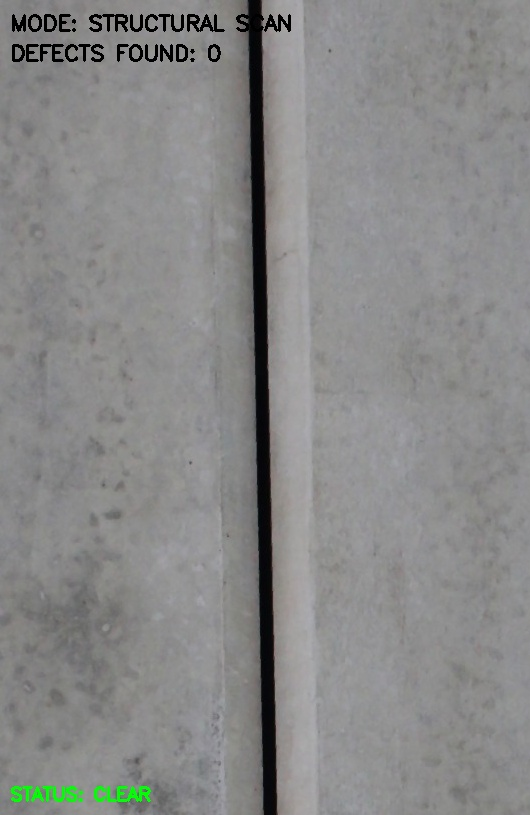


=== JSON report ===
[]

Report entries: 0


In [ ]:

from pathlib import Path
from IPython.display import display, Image as IPyImage
import json

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
stem = "image_0000072_crop_0000002_best_codebrim"

image_path = ROOT / "outputs" / f"{stem}_annotated.jpg"
report_path = ROOT / "outputs" / f"{stem}_report.json"

assert image_path.is_file(), f"Missing annotated image: {image_path}"
assert report_path.is_file(), f"Missing report: {report_path}"

print("=== Annotated image ===")
display(IPyImage(filename=str(image_path)))

print("\n=== JSON report ===")
report = json.loads(report_path.read_text())
print(json.dumps(report, indent=2))
print("\nReport entries:", len(report))


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
test_root = ROOT / "data/codebrim_raw/classification_dataset/test"

classes = ["crack", "spallation", "efflorescence",
           "exposed_bars", "corrosion_stain"]

for class_name in classes:
    folder = test_root / class_name
    images = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ) if folder.exists() else []

    print(f"\n{class_name}: {len(images)} image(s)")
    for image_path in images[:3]:
        print(" ", image_path.relative_to(ROOT))

print("\nSUCCESS: Read-only test-image discovery complete.")



crack: 0 image(s)

spallation: 0 image(s)

efflorescence: 0 image(s)

exposed_bars: 0 image(s)

corrosion_stain: 0 image(s)

SUCCESS: Read-only test-image discovery complete.


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
data_root = ROOT / "data/codebrim_raw/classification_dataset"
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split_name in ["train", "val", "validation", "test"]:
    split = data_root / split_name
    if not split.is_dir():
        continue

    print(f"\n=== {split_name.upper()} ===")
    children = sorted(p for p in split.iterdir() if p.is_dir())
    print("Immediate subdirectories:",
          [p.name for p in children] or "(none)")

    images = [
        p for p in split.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]
    print("Total images:", len(images))

    for p in images[:8]:
        print(" ", p.relative_to(ROOT))

print("\n=== Annotation XML files ===")
for p in sorted((ROOT / "data").rglob("defects.xml")):
    print(p.relative_to(ROOT))

print("\nSUCCESS: Dataset structure inspection complete.")



=== TRAIN ===
Immediate subdirectories: ['background', 'defects']
Total images: 6473
  data/codebrim_raw/classification_dataset/train/background/image_0001024_crop_0000004.png
  data/codebrim_raw/classification_dataset/train/background/image_0000969_crop_0000003.png
  data/codebrim_raw/classification_dataset/train/background/image_0001005_crop_0000005.png
  data/codebrim_raw/classification_dataset/train/background/image_0000966_crop_0000004.png
  data/codebrim_raw/classification_dataset/train/background/image_0000020_crop_0000001.png
  data/codebrim_raw/classification_dataset/train/background/image_0000898_crop_0000005.png
  data/codebrim_raw/classification_dataset/train/background/image_0000861_crop_0000004.png
  data/codebrim_raw/classification_dataset/train/background/image_0000888_crop_0000003.png

=== VAL ===
Immediate subdirectories: ['background', 'defects']
Total images: 616
  data/codebrim_raw/classification_dataset/val/background/image_0000045_crop_0000001.png
  data/codebri

In [ ]:

from pathlib import Path
import xml.etree.ElementTree as ET

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
test_root = ROOT / "data/codebrim_raw/classification_dataset/test"
defects_dir = test_root / "defects"
xml_path = ROOT / "data/codebrim_raw/classification_dataset/metadata/defects.xml"

images = sorted(
    p for p in defects_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

print("Defect images:", len(images))
for p in images[:10]:
    print(p.relative_to(ROOT))

print("\n=== XML structure ===")
if xml_path.exists():
    root = ET.parse(xml_path).getroot()
    print("Root tag:", root.tag)
    print("Root attributes:", root.attrib)
    for child in list(root)[:3]:
        print("Child tag:", child.tag, "| attributes:", child.attrib)
        for item in list(child)[:8]:
            print(" ", item.tag, "=", (item.text or "").strip()[:120])
else:
    print("Annotation XML not found.")

print("\nSUCCESS: Positive-example discovery complete.")


Defect images: 478
data/codebrim_raw/classification_dataset/test/defects/image_0000077_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000084_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000092_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000119_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000127_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000127_crop_0000002.png
data/codebrim_raw/classification_dataset/test/defects/image_0000131_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000131_crop_0000002.png
data/codebrim_raw/classification_dataset/test/defects/image_0000144_crop_0000001.png
data/codebrim_raw/classification_dataset/test/defects/image_0000164_crop_0000001.png

=== XML structure ===
Root tag: Annotation
Root attributes: {}
Child tag: Defect | attributes: {'name': 'image_0000005_crop_000000

In [ ]:

from pathlib import Path
import xml.etree.ElementTree as ET

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
test_root = ROOT / "data/codebrim_raw/classification_dataset/test"
xml_path = ROOT / "data/codebrim_raw/classification_dataset/metadata/defects.xml"

label_names = [
    "Background", "Crack", "Spallation",
    "Efflorescence", "ExposedBars", "CorrosionStain"
]

xml_root = ET.parse(xml_path).getroot()
labels_by_name = {}

for node in xml_root.findall("Defect"):
    labels_by_name[node.attrib.get("name", "")] = {
        child.tag: int((child.text or "0").strip())
        for child in node
    }

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
defect_dir = test_root / "defects"
test_images = sorted(
    p for p in defect_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Test defect images:", len(test_images))
print("\n=== First 10 matched examples ===")

matched = 0
for path in test_images:
    labels = labels_by_name.get(path.name)
    if labels is None:
        continue

    active = [name for name in label_names if labels.get(name, 0) == 1]
    print(path.relative_to(ROOT))
    print("  Ground truth:", active)
    matched += 1

    if matched >= 10:
        break

print("\nMatched examples shown:", matched)
print("SUCCESS: Read-only label matching complete.")


Test defect images: 478

=== First 10 matched examples ===
data/codebrim_raw/classification_dataset/test/defects/image_0000077_crop_0000001.png
  Ground truth: ['Efflorescence', 'CorrosionStain']
data/codebrim_raw/classification_dataset/test/defects/image_0000084_crop_0000001.png
  Ground truth: ['Efflorescence']
data/codebrim_raw/classification_dataset/test/defects/image_0000092_crop_0000001.png
  Ground truth: ['Efflorescence', 'CorrosionStain']
data/codebrim_raw/classification_dataset/test/defects/image_0000119_crop_0000001.png
  Ground truth: ['Efflorescence']
data/codebrim_raw/classification_dataset/test/defects/image_0000127_crop_0000001.png
  Ground truth: ['Efflorescence', 'CorrosionStain']
data/codebrim_raw/classification_dataset/test/defects/image_0000127_crop_0000002.png
  Ground truth: ['Efflorescence', 'CorrosionStain']
data/codebrim_raw/classification_dataset/test/defects/image_0000131_crop_0000001.png
  Ground truth: ['Efflorescence', 'CorrosionStain']
data/codebrim_raw/

In [ ]:

from pathlib import Path
import subprocess
import sys

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
image_path = (
    ROOT / "data/codebrim_raw/classification_dataset/test/defects/"
    / "image_0000164_crop_0000001.png"
)
weights_path = ROOT / "outputs/best_codebrim.pt"

assert image_path.is_file(), f"Image not found: {image_path}"
assert weights_path.is_file(), f"Checkpoint not found: {weights_path}"

result = subprocess.run(
    [
        sys.executable, str(ROOT / "main_demo.py"),
        "--image", str(image_path),
        "--weights", str(weights_path),
    ],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
    timeout=300,
)

print("Return code:", result.returncode)
print("STDOUT:\n", result.stdout)
print("STDERR:\n", result.stderr)

if result.returncode == 0:
    print("\nSUCCESS: Positive-example inference completed.")
else:
    print("\nFAILURE: Review the error before proceeding.")


Return code: 0
STDOUT:
 Found 9 candidate defect(s).
  - efflorescence (0.80) -> cosmetic
  - efflorescence (0.79) -> cosmetic
  - efflorescence (0.71) -> cosmetic
  - crack (0.71) -> watch
  - efflorescence (0.70) -> cosmetic
  - efflorescence (0.66) -> cosmetic
  - efflorescence (0.66) -> cosmetic
  - corrosion_stain (0.64) -> cosmetic
  - efflorescence (0.61) -> cosmetic
Saved -> /content/drive/MyDrive/rodic-poc-project/outputs/image_0000164_crop_0000001_best_codebrim_annotated.jpg
Saved -> /content/drive/MyDrive/rodic-poc-project/outputs/image_0000164_crop_0000001_best_codebrim_report.json

STDERR:
 

SUCCESS: Positive-example inference completed.


=== Original image ===


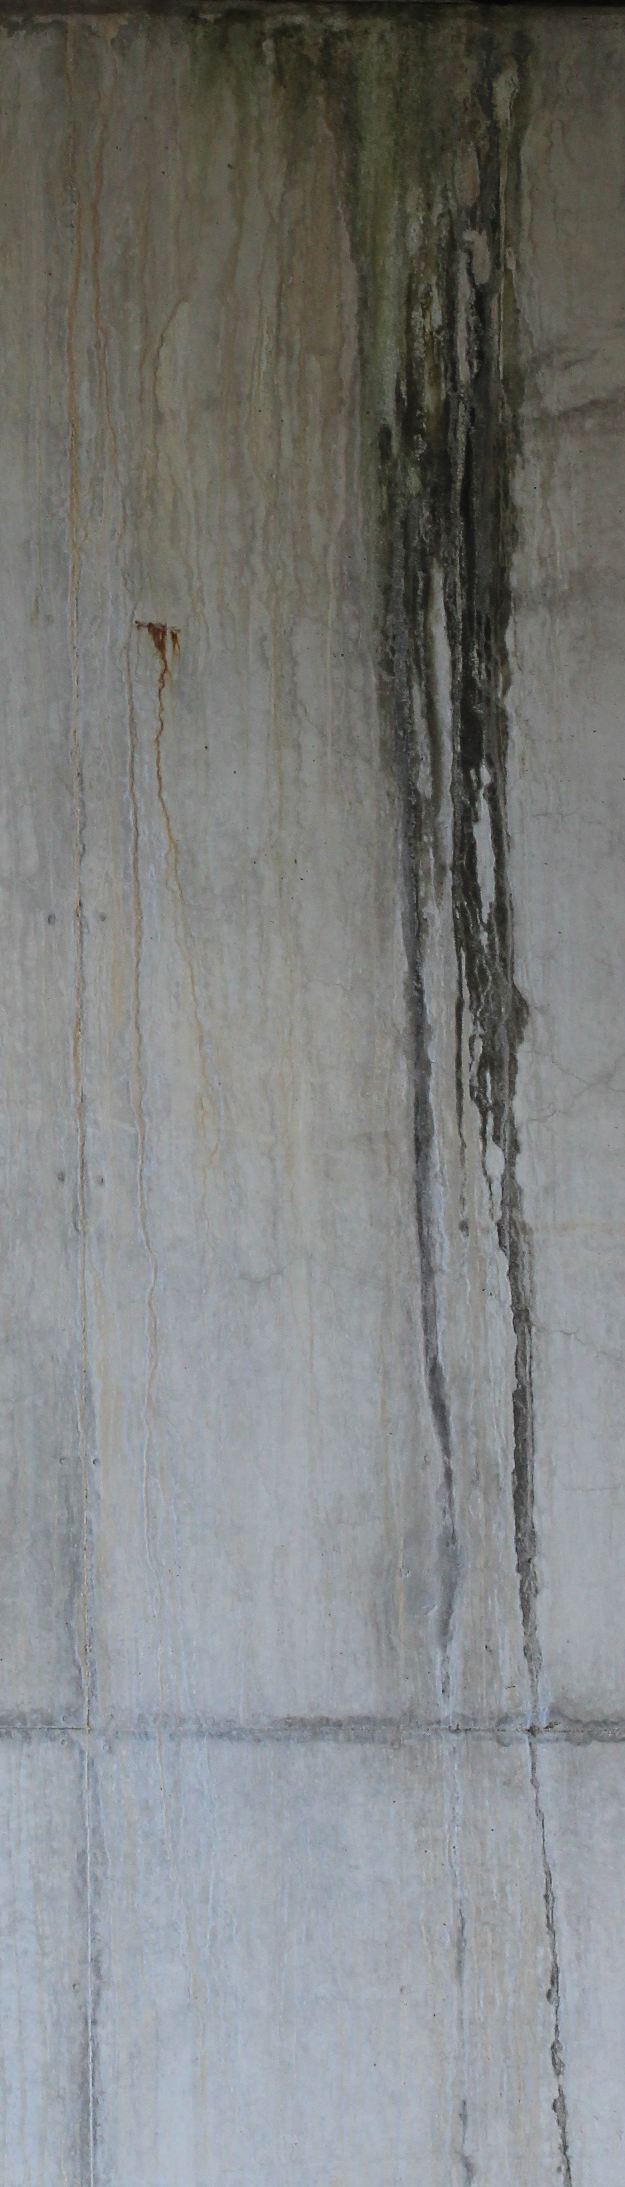

=== Annotated image ===


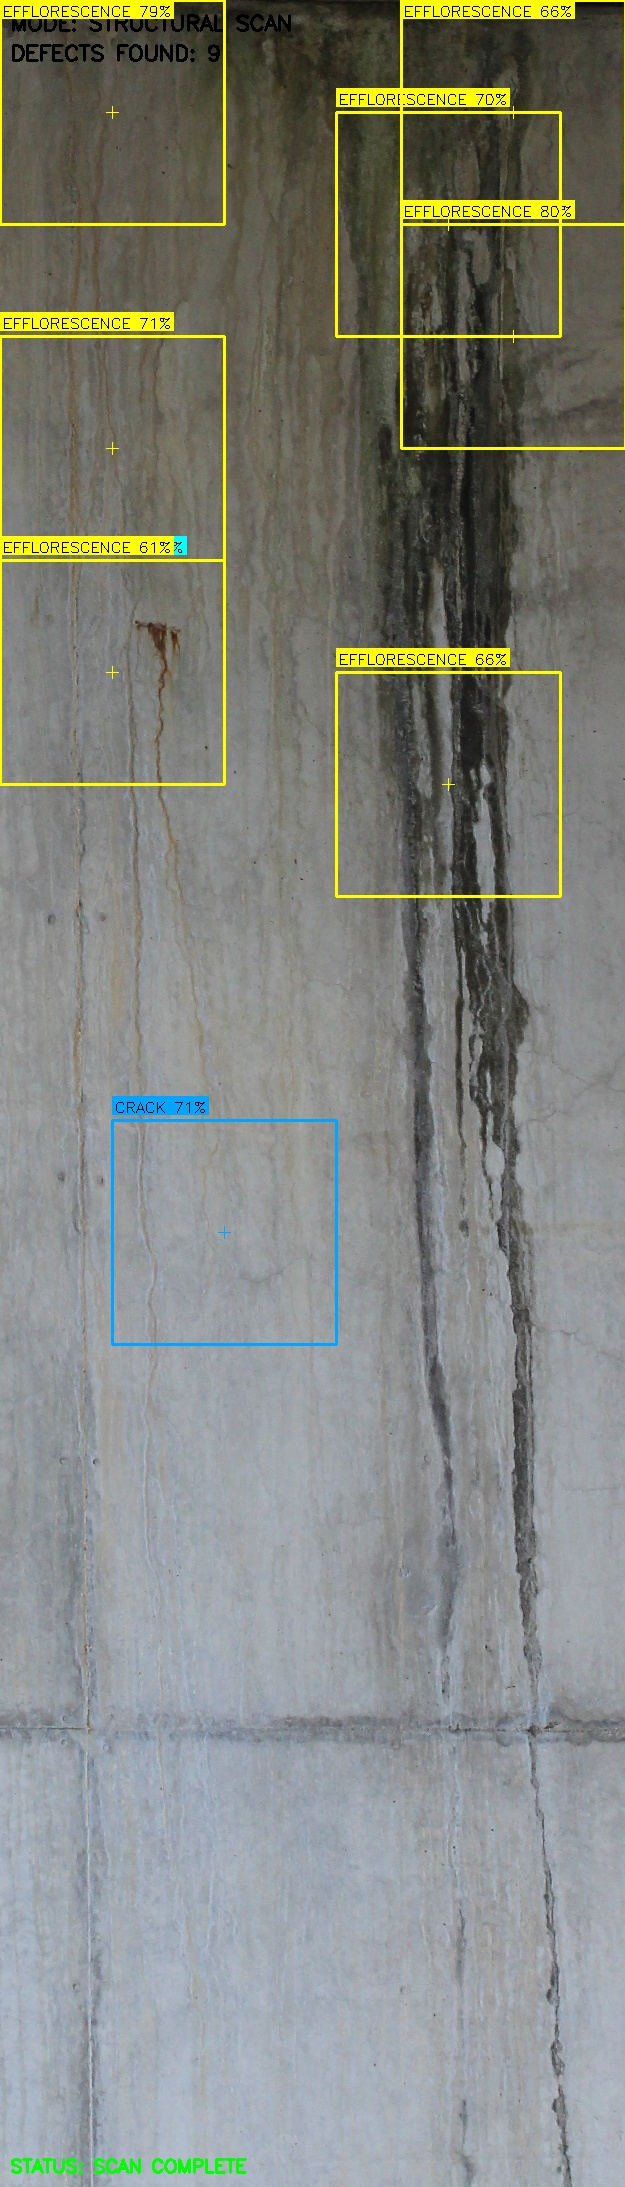


=== Candidate details ===
1. efflorescence | confidence=0.804 | box=[401, 224, 625, 448] | severity=cosmetic
2. efflorescence | confidence=0.792 | box=[0, 0, 224, 224] | severity=cosmetic
3. efflorescence | confidence=0.715 | box=[0, 336, 224, 560] | severity=cosmetic
4. crack | confidence=0.711 | box=[112, 1120, 336, 1344] | severity=watch
5. efflorescence | confidence=0.705 | box=[336, 112, 560, 336] | severity=cosmetic
6. efflorescence | confidence=0.661 | box=[336, 672, 560, 896] | severity=cosmetic
7. efflorescence | confidence=0.660 | box=[401, 0, 625, 224] | severity=cosmetic
8. corrosion_stain | confidence=0.643 | box=[0, 560, 224, 784] | severity=cosmetic
9. efflorescence | confidence=0.607 | box=[0, 560, 224, 784] | severity=cosmetic


In [ ]:

from pathlib import Path
from IPython.display import display, Image as IPyImage
import json

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
stem = "image_0000164_crop_0000001_best_codebrim"

original = (
    ROOT / "data/codebrim_raw/classification_dataset/test/defects/"
    / "image_0000164_crop_0000001.png"
)
annotated = ROOT / "outputs" / f"{stem}_annotated.jpg"
report_path = ROOT / "outputs" / f"{stem}_report.json"

print("=== Original image ===")
display(IPyImage(filename=str(original)))

print("=== Annotated image ===")
display(IPyImage(filename=str(annotated)))

report = json.loads(report_path.read_text())
print("\n=== Candidate details ===")
for i, item in enumerate(report, start=1):
    print(
        f"{i}. {item['class']} | "
        f"confidence={item['confidence']:.3f} | "
        f"box={item['box']} | "
        f"severity={item['severity_band']}"
    )


In [ ]:

from pathlib import Path
from PIL import Image
import json

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
image_path = (
    ROOT / "data/codebrim_raw/classification_dataset/test/defects/"
    / "image_0000164_crop_0000001.png"
)
report_path = (
    ROOT / "outputs/image_0000164_crop_0000001_best_codebrim_report.json"
)

with Image.open(image_path) as image:
    width, height = image.size

report = json.loads(report_path.read_text())

def iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

print(f"Image dimensions: {width} x {height}")
print("\n=== Bounds checks ===")

for i, item in enumerate(report, 1):
    x1, y1, x2, y2 = item["box"]
    valid = (
        0 <= x1 < x2 <= width
        and 0 <= y1 < y2 <= height
    )
    print(
        f"{i}. {item['class']:16} "
        f"box={item['box']} bounds_valid={valid}"
    )

print("\n=== Same-class overlapping candidates (IoU >= 0.10) ===")
pairs = 0
for i in range(len(report)):
    for j in range(i + 1, len(report)):
        if report[i]["class"] != report[j]["class"]:
            continue
        score = iou(report[i]["box"], report[j]["box"])
        if score >= 0.10:
            print(f"{i+1} vs {j+1}: IoU={score:.3f}")
            pairs += 1

if pairs == 0:
    print("No same-class pairs met the IoU threshold.")

print("\nSUCCESS: Bounds and overlap diagnostics complete.")


Image dimensions: 625 x 2187

=== Bounds checks ===
1. efflorescence    box=[401, 224, 625, 448] bounds_valid=True
2. efflorescence    box=[0, 0, 224, 224] bounds_valid=True
3. efflorescence    box=[0, 336, 224, 560] bounds_valid=True
4. crack            box=[112, 1120, 336, 1344] bounds_valid=True
5. efflorescence    box=[336, 112, 560, 336] bounds_valid=True
6. efflorescence    box=[336, 672, 560, 896] bounds_valid=True
7. efflorescence    box=[401, 0, 625, 224] bounds_valid=True
8. corrosion_stain  box=[0, 560, 224, 784] bounds_valid=True
9. efflorescence    box=[0, 560, 224, 784] bounds_valid=True

=== Same-class overlapping candidates (IoU >= 0.10) ===
1 vs 5: IoU=0.216
5 vs 7: IoU=0.216

SUCCESS: Bounds and overlap diagnostics complete.


image_0000164_crop_0000001.png


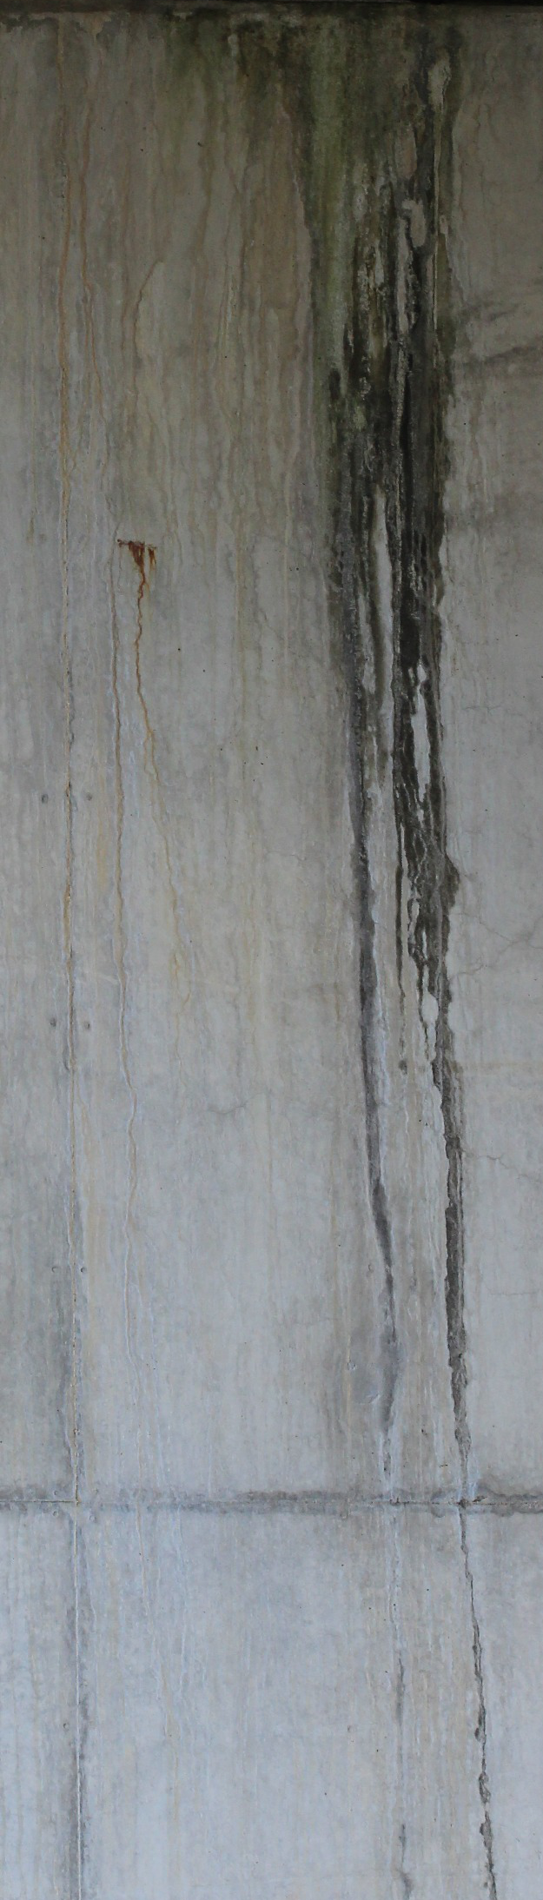

image_0000164_crop_0000001_best_codebrim_annotated.jpg


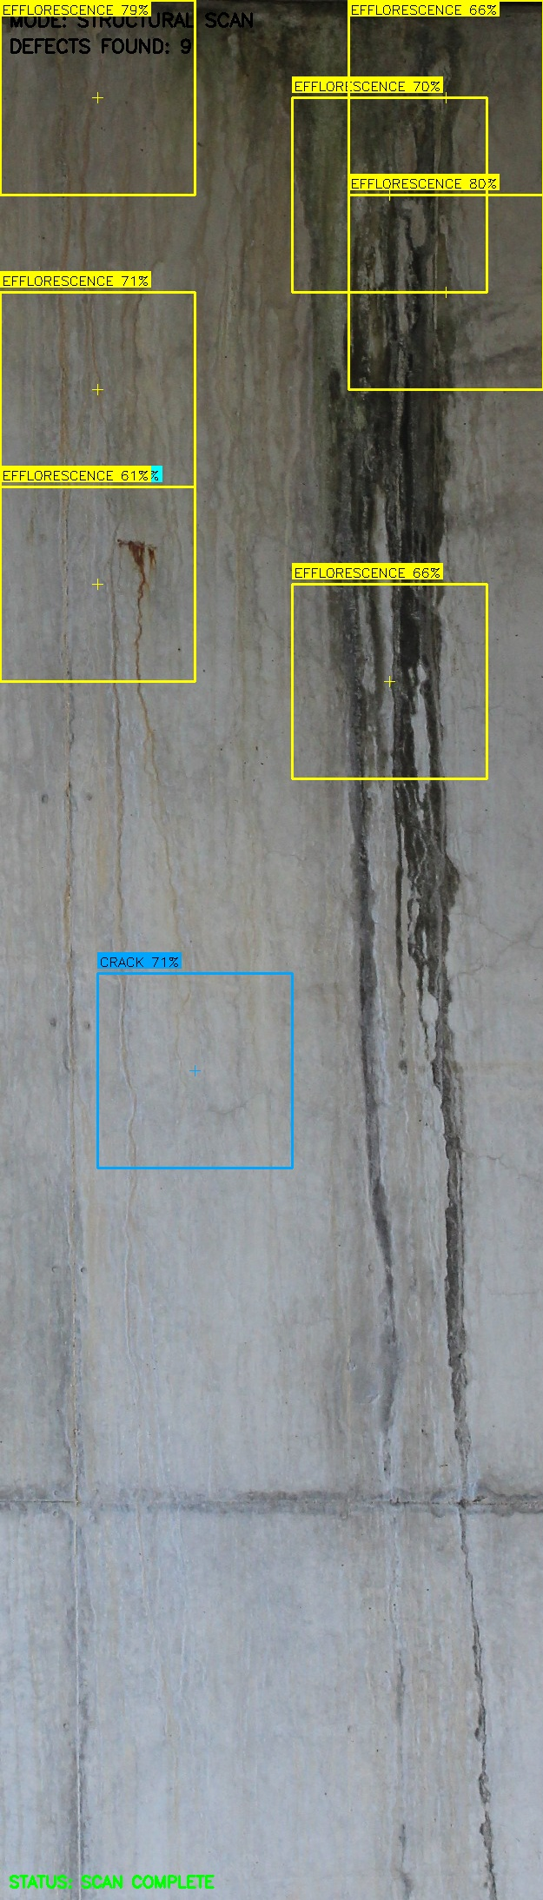

In [ ]:

from pathlib import Path
from PIL import Image
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
paths = [
    ROOT / "data/codebrim_raw/classification_dataset/test/defects/"
    / "image_0000164_crop_0000001.png",
    ROOT / "outputs/image_0000164_crop_0000001_best_codebrim_annotated.jpg",
]

for path in paths:
    print(path.name)
    with Image.open(path) as im:
        preview = im.copy()
        preview.thumbnail((1600, 1900))
        display(preview)


In [ ]:

import inspect
import main_demo
import src.sliding_window as sliding_window

print("Demo entry points:")
for name in ("main", "run_demo", "parse_args"):
    obj = getattr(main_demo, name, None)
    if callable(obj):
        try:
            print(f"\nmain_demo.{name}{inspect.signature(obj)}")
        except (TypeError, ValueError):
            print(f"\nmain_demo.{name}: signature unavailable")

print("\nCurrent detect signature:")
print(inspect.signature(sliding_window.detect))

print("\nDemo source — first 180 lines:")
source_lines = inspect.getsource(main_demo).splitlines()
for i, line in enumerate(source_lines[:180], start=1):
    print(f"{i:03}: {line}")


Demo entry points:

main_demo.main(image_path: str, weights_path: str) -> None

Current detect signature:
(image, model, device, class_names, multi_label=True, window_size=224, stride=112, confidence_threshold=0.6, nms_iou_threshold=0.3) -> List[src.sliding_window.Detection]

Demo source — first 180 lines:
001: import argparse
002: import json
003: from pathlib import Path
004: 
005: import cv2
006: import torch
007: from PIL import Image
008: 
009: from src import config
010: from src.model import build_model
011: from src.sliding_window import detect
012: from src.overlay import draw_overlay
013: from src.severity_stub import heuristic_severity
014: 
015: 
016: def main(image_path: str, weights_path: str) -> None:
017:     device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
018:     checkpoint = torch.load(weights_path, map_location=device)
019:     task = checkpoint["task"]
020:     multi_label = task == "codebrim"
021:     class_names = config.CODEBRIM_CLASSES if 

In [ ]:

from pathlib import Path
import json
import main_demo
import src.config as config
import src.sliding_window as sliding_window
ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
# Existing test image and frozen checkpoint
image_path = Path(
   ROOT/"data/codebrim_raw/classification_dataset/test/defects/image_0000092_crop_0000001.png"
)
weights_path = Path(ROOT/"outputs/best_codebrim.pt")

assert image_path.exists(), f"Image not found: {image_path}"
assert weights_path.exists(), f"Checkpoint not found: {weights_path}"

# Separate experiment output directory
experiment_dir = Path("outputs/localization_experiment")
experiment_dir.mkdir(parents=True, exist_ok=True)

# Preserve the original in-memory references
original_detect = main_demo.detect
original_output_dir = config.OUTPUT_DIR

def detect_keep_proposals(
    image, model, device, class_names, multi_label=True
):
    return sliding_window.detect(
        image,
        model,
        device,
        class_names,
        multi_label=multi_label,
        window_size=config.WINDOW_SIZE,
        stride=config.WINDOW_STRIDE,
        confidence_threshold=config.CONFIDENCE_THRESHOLD,
        nms_iou_threshold=1.0,
    )

try:
    main_demo.detect = detect_keep_proposals
    config.OUTPUT_DIR = experiment_dir

    main_demo.main(str(image_path), str(weights_path))
finally:
    main_demo.detect = original_detect
    config.OUTPUT_DIR = original_output_dir

print("\nExperiment files:")
for path in sorted(experiment_dir.glob("*")):
    print(f"{path} — {path.stat().st_size:,} bytes")


Found 10 candidate defect(s).
  - crack (0.94) -> watch
  - efflorescence (0.89) -> cosmetic
  - crack (0.88) -> watch
  - efflorescence (0.80) -> cosmetic
  - efflorescence (0.75) -> cosmetic
  - efflorescence (0.68) -> cosmetic
  - corrosion_stain (0.64) -> cosmetic
  - efflorescence (0.64) -> cosmetic
  - efflorescence (0.61) -> cosmetic
  - efflorescence (0.61) -> cosmetic
Saved -> outputs/localization_experiment/image_0000092_crop_0000001_best_codebrim_annotated.jpg
Saved -> outputs/localization_experiment/image_0000092_crop_0000001_best_codebrim_report.json

Experiment files:
outputs/localization_experiment/image_0000092_crop_0000001_best_codebrim_annotated.jpg — 484,217 bytes
outputs/localization_experiment/image_0000092_crop_0000001_best_codebrim_report.json — 3,557 bytes


In [ ]:

# STEP 3 — Dynamic INT8 compatibility check
# Read-only: does not load or overwrite project checkpoints.

from pathlib import Path
import torch
import torch.nn as nn

ROOT = Path("/content/drive/MyDrive/rodic-poc-project")
OUT = ROOT / "outputs"

try:
    assert ROOT.exists(), f"Project root not found: {ROOT}"
    assert (OUT / "edge_baseline_benchmark.json").exists(), \
        "Baseline report not found."

    print("PyTorch version:", torch.__version__)
    print("Device: CPU")
    print("Dynamic quantization API:",
          hasattr(torch.ao.quantization, "quantize_dynamic"))

    # Verify quantization on a disposable Linear-layer model.
    test_model = nn.Sequential(
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 6)
    ).eval()

    test_input = torch.randn(1, 128)

    with torch.inference_mode():
        fp32_output = test_model(test_input)

    int8_model = torch.ao.quantization.quantize_dynamic(
        test_model,
        {nn.Linear},
        dtype=torch.qint8
    ).eval()

    with torch.inference_mode():
        int8_output = int8_model(test_input)

    max_abs_diff = (fp32_output - int8_output).abs().max().item()
    quantized_linear_layers = sum(
        "quantized" in type(module).__module__.lower()
        for module in int8_model.modules()
        if isinstance(module, nn.Module)
    )

    print("FP32 output shape:", tuple(fp32_output.shape))
    print("INT8 output shape:", tuple(int8_output.shape))
    print("Maximum absolute output difference:", round(max_abs_diff, 6))
    print("Quantized module types:",
          sorted({type(m).__name__ for m in int8_model.modules()}))

    print("\nSUCCESS: Dynamic INT8 compatibility check completed; "
          "original project files unchanged.")

except Exception as e:
    print(f"\nFAILED: {type(e).__name__}: {e}")


PyTorch version: 2.11.0+cu130
Device: CPU
Dynamic quantization API: True
FP32 output shape: (1, 6)
INT8 output shape: (1, 6)
Maximum absolute output difference: 0.009075
Quantized module types: ['Linear', 'LinearPackedParams', 'ReLU', 'Sequential']

SUCCESS: Dynamic INT8 compatibility check completed; original project files unchanged.


/tmp/ipykernel_3052/323834871.py:33: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.ao.quantization.quantize_dynamic(
